# 1. Data cleaning, preparation and aggregation

This notebook transforms the data to behavior-test instances and filters these trough the described data cleaning process

## Preparation

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import matplotlib.dates as mdates

# Make sure that all columns are visible when a dataframe is printed
pd.set_option('display.max_columns', None)

In [4]:
# Read the raw COVID-radar data
df_radar = pd.read_csv("data/COVID_radar_data/CRdataShared.csv")

# Make sure the date column is a datetime object
df_radar['date'] = pd.to_datetime(df_radar['date'], format='%d%b%Y')

df_radar.head()

,gender,age,profession,contact,cough,sorethroat,fever,shortofbreath,bowelsymptoms,chestsymptoms,eyesymptoms,lossofsmell,fatigue,headache,vaccine,outhousework,outofhouse,numberpersons5m,numbervisitors,numberpersons150cm,numberpersons150cmspoken,mask,public,holiday,brainfog,depressed,date,fatigueExtreme,sport,ID,positivetest,numbertimescovid,firstpositivetest,dayssurroundingpositivetest,everpositive,negativetest,numbernegativetest,firstnegativetest,dayssurroundingnegativetest,evernegativetest,evercovidinapp,evercovidoutapp
0,f,06-11,NaN,0,1,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,0.0,1,2,0,0,NaN,NaN,NaN,NaN,NaN,2020-04-05,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
1,f,06-11,NaN,0,1,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,5.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2020-04-06,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
2,f,06-11,NaN,0,0,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,5.0,1,0,5,0,NaN,NaN,NaN,NaN,NaN,2020-04-08,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
3,f,06-11,NaN,0,0,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,0.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2020-04-15,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0
4,f,06-11,NaN,0,0,0,0,0,0,0,0.0,0,NaN,NaN,NaN,0,0.0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,2020-05-14,NaN,NaN,1,0,0,0,NaN,0,0,0,0,NaN,0,NaN,0


In [ ]:
df_grouped = df_radar.groupby("ID")["profession"].first()
df_grouped.value_counts(dropna=False)

profession
None             253963
other             19875
hcpro              3620
pensioner          2374
education          2020
other_contact      1589
catering            365
student             220
Name: count, dtype: int64

In [6]:
df_grouped.isna().sum()

np.int64(253963)

In [7]:
len(df_grouped)

284026

In [9]:
# Calculate summary staistics for the data

nr_pos_tests = sum(df_radar["positivetest"])
nr_neg_tests = sum(df_radar["negativetest"])
nr_total_tests = nr_pos_tests + nr_neg_tests
nr_users = len(df_radar["ID"].unique())

print(f"Nr tests left: {nr_total_tests}, \n"
      f"Nr positive: {nr_pos_tests}, \n"
      f"Nr negative: {nr_neg_tests}, \n"
      f"Nr users left: {nr_users}")

Nr tests left: 38548, 
Nr positive: 5803, 
Nr negative: 32745, 
Nr users left: 284026


## Generate all instances of behaviour and test result

In [ ]:
# Get unique IDs and dates
unique_ids = df_radar['ID'].unique()
unique_dates = df_radar['date'].unique()

# For all dates, calculate which dates should be in the baseline period if that date is taken as the test date
date_ranges = {
    t0: [(t0 - pd.Timedelta(days=(18 - t))) for t in range(14)] for t0 in unique_dates
}

# Check if the date ranges are correct
# The result is a dictionary with each test date as the key and the dates in the baseline period the values (in a list)
#date_ranges

Extract all behavior during the baseline period for all tests performed.

In [ ]:
results = []

# Filter df_radar to only include rows with a test result
df_radar_with_tests = df_radar[(df_radar['positivetest'] == 1) | (df_radar['negativetest'] == 1)]

# Get all dates and IDs from persons who tested
unique_dates = df_radar['date'].unique()
test_ids = df_radar_with_tests['ID'].unique()

# Batch processing was used such that a progress bar could be used
batch_size = 5000

# Loop over all IDs that performed a test in batches
for i in tqdm(range(0, len(test_ids), batch_size)):
    
    # Get the correct IDs and extract all surveys for those IDS
    batch_ids = list(test_ids)[i:i + batch_size]
    batch_data = df_radar[df_radar['ID'].isin(batch_ids)]

    # For each t0 (test) date
    for t0_date in unique_dates:
        
        # Get the date range as made in the previous cell (baseline period)
        tf_dates = date_ranges.get(t0_date, [])

        # Get the corresponding surveys that are in the baseline periods
        tf_data = batch_data[batch_data['date'].isin(tf_dates)]

        # Create columns for numbervisitors and numberpersons150cm and fill them with the correct values
        tf_summary = tf_data.pivot_table(
            index="ID",
            columns="date",
            values=["numbervisitors", "numberpersons150cm"]
        )
        tf_summary.columns = [
            f"{col[0]}_T{(col[1] - t0_date).days}" for col in tf_summary.columns
        ]
        tf_summary = tf_summary.reset_index()

        # Add T0_date column
        tf_summary['T0_date'] = t0_date

        # Get all tests performed at the current t0 date
        test_subset = df_radar_with_tests[df_radar_with_tests['date'] == t0_date]
        test_subset = test_subset[['ID', 'positivetest', 'negativetest']].drop_duplicates()
        
        # Merge test results with the correct behavioral data
        merged_summary = test_subset.merge(tf_summary, on='ID', how='left')

        # Append the results for this t0 date
        results.append(merged_summary)

# Concatenate the results of all t0 dates
df_final = pd.concat(results, ignore_index=True)

df_merged2 = pd.merge(df_final, df_radar[['ID', 'date', 'age', 'profession', 'positivetest', 'negativetest']], 
                     left_on=['ID', 'T0_date'], right_on=['ID', 'date'], how='inner')

df_merged2 = df_merged2.drop(columns=['positivetest_y', 'negativetest_y'])

df_merged2.rename(columns={'positivetest_x': 'positivetest', 'negativetest_x': 'negativetest'}, inplace=True)

df_merged2

100%|██████████| 5/5 [02:12<00:00, 26.46s/it]


,ID,positivetest,negativetest,T0_date,numberpersons150cm_T-5,numbervisitors_T-5,numberpersons150cm_T-12,numberpersons150cm_T-11,numberpersons150cm_T-10,numberpersons150cm_T-9,numberpersons150cm_T-8,numberpersons150cm_T-7,numberpersons150cm_T-6,numbervisitors_T-12,numbervisitors_T-11,numbervisitors_T-10,numbervisitors_T-9,numbervisitors_T-8,numbervisitors_T-7,numbervisitors_T-6,numberpersons150cm_T-18,numberpersons150cm_T-17,numberpersons150cm_T-16,numberpersons150cm_T-15,numberpersons150cm_T-14,numberpersons150cm_T-13,numbervisitors_T-18,numbervisitors_T-17,numbervisitors_T-16,numbervisitors_T-15,numbervisitors_T-14,numbervisitors_T-13,date,age,profession
0,8072,1,0,2020-04-08,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-08,40-49,NaN
1,46069,1,0,2020-04-08,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-08,50-59,NaN
2,50498,1,0,2020-04-08,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-08,19-29,NaN
3,7596,1,0,2020-04-15,0.0,0.0,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-15,30-39,NaN
4,12736,1,0,2020-04-15,0.0,20.0,NaN,NaN,NaN,NaN,2.0,0.0,9.0,NaN,NaN,NaN,NaN,0.0,2.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-04-15,60-69,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27414,278633,0,1,2022-02-23,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,2022-02-23,50-59,other
27415,279687,1,0,2022-02-25,NaN,NaN,10.0,NaN,3.0,2.0,2.0,2.0,3.0,0.0,NaN,3.0,0.0,0.0,0.0,0.0,NaN,3.0,3.0,1.0,2.0,NaN,NaN,0.0,0.0,1.0,2.0,NaN,2022-02-25,60-69,other
27416,283688,1,0,2022-02-25,NaN,NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2022-02-25,40-49,education
27417,279808,0,1,2022-02-28,NaN,NaN,0.0,1.0,NaN,0.0,3.0,0.0,2.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,1.0,NaN,0.0,NaN,3.0,0.0,0.0,NaN,0.0,NaN,0.0,2022-02-28,70-79,other


Tests for which no behavior was found were not added, therefore they will be added here

In [12]:
# Get all behavior columns
behavior_columns = [col for col in df_merged2.columns if "numbervisitors_T" in col or "numberpersons150cm_T" in col]

# Identify tests that were not in merged_df2 (Tests are uniquely identified by the ID and date combination)
missing_tests = df_radar_with_tests[~df_radar_with_tests.set_index(['ID', 'date']).index.isin(df_merged2.set_index(['ID', 'T0_date']).index)]

# Get the ID, date and test result of the missing tests
df_missing_tests = missing_tests[['ID', 'date', 'age', 'profession', 'positivetest', 'negativetest']].copy()
df_missing_tests.rename(columns={'date': 'T0_date'}, inplace=True)

# Add behavior columns and fill them with NaN values
for col in behavior_columns:
    df_missing_tests[col] = pd.NA

# Concatonate the tests without surveys in the exposure period to the already found tests
df_complete = pd.concat([df_merged2, df_missing_tests], ignore_index=True)

df_complete = df_complete.drop(columns=['date'])

df_complete

C:\Users\schootui\AppData\Local\Temp\ipykernel_26236\1807583626.py:16: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_complete = pd.concat([df_merged2, df_missing_tests], ignore_index=True)


,ID,positivetest,negativetest,T0_date,numberpersons150cm_T-5,numbervisitors_T-5,numberpersons150cm_T-12,numberpersons150cm_T-11,numberpersons150cm_T-10,numberpersons150cm_T-9,numberpersons150cm_T-8,numberpersons150cm_T-7,numberpersons150cm_T-6,numbervisitors_T-12,numbervisitors_T-11,numbervisitors_T-10,numbervisitors_T-9,numbervisitors_T-8,numbervisitors_T-7,numbervisitors_T-6,numberpersons150cm_T-18,numberpersons150cm_T-17,numberpersons150cm_T-16,numberpersons150cm_T-15,numberpersons150cm_T-14,numberpersons150cm_T-13,numbervisitors_T-18,numbervisitors_T-17,numbervisitors_T-16,numbervisitors_T-15,numbervisitors_T-14,numbervisitors_T-13,age,profession
0,8072,1,0,2020-04-08,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40-49,NaN
1,46069,1,0,2020-04-08,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50-59,NaN
2,50498,1,0,2020-04-08,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19-29,NaN
3,7596,1,0,2020-04-15,0.0,0.0,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30-39,NaN
4,12736,1,0,2020-04-15,0.0,20.0,NaN,NaN,NaN,NaN,2.0,0.0,9.0,NaN,NaN,NaN,NaN,0.0,2.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60-69,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38543,283806,0,1,2022-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70-79,other
38544,283834,0,1,2021-04-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30-39,other
38545,283890,0,1,2021-11-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50-59,NaN
38546,283943,0,1,2021-12-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60-69,NaN


In [13]:
# Save the dataframe to a csv for quicker runtimes
df_complete.to_csv("data/all_tests_behavior.csv", index=False)

## 2. Cleaning the behavior-test instances

In [3]:
df_inst = pd.read_csv("data/all_tests_behavior.csv")

df_inst['T0_date'] = pd.to_datetime(df_inst['T0_date'])

# Print how many tests are left
print(f"Nr tests left: {len(df_inst)}, \n"
      f"Nr positive: {sum(df_inst['positivetest'])}, \n"
      f"Nr negative: {sum(df_inst['positivetest'] == 0)}, \n"
      f"Nr users left: {len(df_inst['ID'].unique())}.")

Nr tests left: 38548, 
Nr positive: 5803, 
Nr negative: 32745, 
Nr users left: 21160.


### Remove tests from IDs where the age or gender changed in any of their entries in the full COVID-Radar dataset

In [16]:
df_clean_inconsistent = df_inst.copy()

# Get all IDs for which the gender or age changed at least once
inconsistent_ids = df_radar.groupby('ID').agg({
    'gender': pd.Series.nunique,
    'age': pd.Series.nunique
})

inconsistent_ids = inconsistent_ids[(inconsistent_ids['gender'] > 1) | (inconsistent_ids['age'] > 1)].index.tolist()

df_clean_inconsistent = df_clean_inconsistent[~df_clean_inconsistent['ID'].isin(inconsistent_ids)]

# Print how many tests are left
print(f"Nr tests left: {len(df_clean_inconsistent)}, \n"
      f"Nr positive: {sum(df_clean_inconsistent['positivetest'])}, \n"
      f"Nr negative: {sum(df_clean_inconsistent['positivetest'] == 0)}, \n"
      f"Nr users left: {len(df_clean_inconsistent['ID'].unique())}")

Nr tests left: 38118, 
Nr positive: 5739, 
Nr negative: 32379, 
Nr users left: 20928


### Remove negative tests which occur witin 14 days before, or 99 days after a positive test

In [17]:
df_clean_negatives = df_clean_inconsistent.copy()

df_clean_negatives = df_clean_negatives[(df_clean_negatives["positivetest"] == 1) | (df_clean_negatives["negativetest"] == 1)]

time_window_before = 14
time_window_after = 99

# Create a column to flag which rows to remove
df_clean_negatives['remove'] = 0

# Loop over all persons
for person_id, person_rows in tqdm(df_clean_negatives.groupby('ID')):
    # Find all positive tests for this person
    positive_tests = person_rows[person_rows['positivetest'] == 1]
    # Loop over all positive tests for this person (idx can be ignored)
    for idx, positive_row in positive_tests.iterrows():
        positive_date = positive_row['T0_date']
        
        # Mark negative tests within 14 days before the positive test
        negatives_before = person_rows[
            (person_rows['T0_date'] >= positive_date - pd.Timedelta(days=time_window_before)) &
            (person_rows['T0_date'] < positive_date) &
            (person_rows['positivetest'] == 0)
        ]
        df_clean_negatives.loc[negatives_before.index, 'remove'] = 1
        
        # Mark negative tests within 99 days after the positive test
        negatives_after = person_rows[
            (person_rows['T0_date'] > positive_date) &
            (person_rows['T0_date'] <= positive_date + pd.Timedelta(days=time_window_after)) &
            (person_rows['positivetest'] == 0)
        ]
        df_clean_negatives.loc[negatives_after.index, 'remove'] = 1

# Filter out marked rows
df_clean_negatives = df_clean_negatives[df_clean_negatives['remove'] == 0].drop(columns=['remove'])

# Print how many tests are left
print(f"Nr tests left: {len(df_clean_negatives)}, \n"
      f"Nr positive: {sum(df_clean_negatives['positivetest'])}, \n"
      f"Nr negative: {sum(df_clean_negatives['positivetest'] == 0)}, \n"
      f"Nr users left: {len(df_clean_negatives['ID'].unique())}")

100%|██████████| 20928/20928 [00:24<00:00, 861.68it/s] 

Nr tests left: 37053, 
Nr positive: 5739, 
Nr negative: 31314, 
Nr users left: 20928


### Remove data from before it was possible to report a negative test

In [18]:
df_clean_first_negative = df_clean_negatives.copy()

# Filter for the rows where a negative test was reported
negative_tests = df_radar[df_radar['negativetest'] == 1]

# Find the earliest date where a negative test was reported
first_negative_test_date = negative_tests['date'].min()

# Print the earliest date for the negative test
print(f"The first negative test was reported on: {first_negative_test_date}")

# Only select tests occuring after this date from the original data
df_clean_first_negative = df_clean_first_negative[df_clean_first_negative['T0_date'] >= first_negative_test_date]

# Print how many tests are left
print(f"Nr tests left: {len(df_clean_first_negative)}, \n"
      f"Nr positive: {sum(df_clean_first_negative['positivetest'])}, \n"
      f"Nr negative: {sum(df_clean_first_negative['positivetest'] == 0)}, \n"
      f"Nr users left: {len(df_clean_first_negative['ID'].unique())}")

The first negative test was reported on: 2021-01-15 00:00:00
Nr tests left: 34404, 
Nr positive: 3090, 
Nr negative: 31314, 
Nr users left: 18946


### Remove tests from users who reported that they are healthcare professionals or work in education

In [19]:
df_clean_professions = df_clean_first_negative

print(df_radar["profession"].unique())
print(df_radar["profession"].value_counts(dropna = False))

print(df_clean_professions["profession"].value_counts(dropna = False))

df_grouped = df_clean_professions.groupby("ID")["profession"].first()
print(df_grouped.value_counts(dropna=False))

df_clean_professions = df_clean_professions[~df_clean_professions["profession"].isin(["hcpro", "education"])]

# Print how many tests are left
print(f"Nr tests left: {len(df_clean_professions)}, \n"
      f"Nr positive: {sum(df_clean_professions['positivetest'])}, \n"
      f"Nr negative: {sum(df_clean_professions['positivetest'] == 0)}, \n"
      f"Nr users left: {len(df_clean_professions['ID'].unique())}")

[nan 'other' 'hcpro' 'education' 'pensioner' 'other_contact' 'student'
 'catering']
profession
NaN              4730795
other            2708862
hcpro             425192
pensioner         258439
education         256549
other_contact     140804
catering           26630
student             3304
Name: count, dtype: int64
profession
NaN              13981
other            12736
hcpro             3047
education         1971
pensioner         1445
other_contact      931
catering           202
student             91
Name: count, dtype: int64
profession
None             8094
other            6918
hcpro            1504
education         926
pensioner         851
other_contact     482
catering          108
student            63
Name: count, dtype: int64
Nr tests left: 29386, 
Nr positive: 2675, 
Nr negative: 26711, 
Nr users left: 16516


In [ ]:
df_clean_professions.to_csv("data/df_clean_professions.csv")

### Remove tests from persons that are not 50-79 years of age

In [ ]:
df_clean_age = df_clean_professions.copy()

df_clean_age = df_clean_age[df_clean_age["age"].isin(['50-59', '60-69', '70-79'])]


# Print how many tests are left
print(f"Nr tests left: {len(df_clean_age)}, \n"
      f"Nr positive: {sum(df_clean_age['positivetest'])}, \n"
      f"Nr negative: {sum(df_clean_age['positivetest'] == 0)}, \n"
      f"Nr users left: {len(df_clean_age['ID'].unique())}")

Nr tests left: 22113, 
Nr positive: 1848, 
Nr negative: 20265, 
Nr users left: 12402


### Remove tests where there were more than x NaN values in the baseline period

In [21]:
df_clean_professions = df_clean_age.copy()
#df_clean_professions

Calculate aggregate values for the behavior columns

In [ ]:
df_clean_x_nan = df_clean_professions.copy()

# Get all visitor and persons within 150cm columns
person_columns = sorted(
    [col for col in df_clean_x_nan.columns if col.startswith("numberpersons150cm_T")],
    key=lambda x: int(x.split("_T")[-1])
)
visitor_columns = sorted(
    [col for col in df_clean_x_nan.columns if col.startswith("numbervisitors_T")],
    key=lambda x: int(x.split("_T")[-1])
)

# Calculate the number of NaN values for each contact counts
na_counts_visitors = df_clean_x_nan[visitor_columns].isna().sum(axis=1)
na_counts_persons = df_clean_x_nan[person_columns].isna().sum(axis=1)

# Calculate the number of values greater than 0
gt0_counts_visitors = (df_clean_x_nan[visitor_columns] > 0).sum(axis=1)
gt0_counts_persons = (df_clean_x_nan[person_columns] > 0).sum(axis=1)

df_clean_x_nan['na_counts_visitors'] = na_counts_visitors
df_clean_x_nan['na_counts_persons'] = na_counts_persons
df_clean_x_nan['gt0_counts_visitors'] = gt0_counts_visitors
df_clean_x_nan['gt0_counts_persons'] = gt0_counts_persons

# Calculate the sum of visitors and others during exposure period
df_clean_x_nan['sum_visitors_ep'] = df_clean_x_nan[visitor_columns].sum(axis=1, skipna=True)
df_clean_x_nan['sum_others_ep'] = df_clean_x_nan[person_columns].sum(axis=1, skipna=True)

EXTRA: Check how many rows are left for each number of threshold of max NaN

In [23]:
rows_left = []

# Loop through max_nr_nan values from 0 to 10
for max_nr_nan in range(15):
    # Filter rows where the number of NaNs per row is less than or equal to the current max_nr_nan
    df_filtered = df_clean_x_nan[df_clean_x_nan["na_counts_visitors"] <= max_nr_nan]
    
    # Gather more information about the filtered data and append it.
    rows_left.append({"Threshold": max_nr_nan,
                      "Tests": len(df_filtered),
                      "Positive": sum(df_filtered["positivetest"]),
                      "Negative": sum(df_filtered["negativetest"]),
                      "%-Positive": round(sum(df_filtered["positivetest"]) / len(df_filtered) * 100, 2),
                      "Users": len(df_filtered['ID'].unique())},)

# Collect the results in a dataframe
df_rows_left = pd.DataFrame(rows_left)

# Calculate the difference compared to the previous value
df_rows_left['Tests Diff'] = df_rows_left['Tests'].diff().fillna(0).astype(int)
df_rows_left['Users Diff'] = df_rows_left['Users'].diff().fillna(0).astype(int)

df_rows_left

,Threshold,Tests,Positive,Negative,%-Positive,Users,Tests Diff,Users Diff
0,0,814,91,723,11.18,619,0,0
1,1,1556,158,1398,10.15,1087,742,468
2,2,2195,210,1985,9.57,1448,639,361
3,3,2742,254,2488,9.26,1774,547,326
4,4,3281,299,2982,9.11,2071,539,297
5,5,3814,347,3467,9.10,2369,533,298
6,6,4332,395,3937,9.12,2661,518,292
7,7,4891,447,4444,9.14,2992,559,331
8,8,5468,503,4965,9.20,3323,577,331
9,9,6230,569,5661,9.13,3815,762,492


## Preparation: Fill in all NaN values with the average of the baseline period

A new dataset is created containing the behavior-test instances for each threshold value from 0 to 4

In [ ]:
# Filter only the wanted columns from the full dataset
df_fill_nan_all = df_clean_x_nan.copy()

# Compute the mean number of visitors and other contacts per row
df_fill_nan_all["persons_mean"] = df_fill_nan_all[person_columns].mean(axis=1, skipna=True)
df_fill_nan_all["visitors_mean"] = df_fill_nan_all[visitor_columns].mean(axis=1, skipna=True)

# Fill NaNs with the per-row mean
for col in person_columns:
    df_fill_nan_all[col] = df_fill_nan_all[col].fillna(df_fill_nan_all["persons_mean"])

for col in visitor_columns:
    df_fill_nan_all[col] = df_fill_nan_all[col].fillna(df_fill_nan_all["visitors_mean"])

# Loop through different thresholds of allowed original NaNs (before filling)
for max_nr_nan in range(0, 5):
    df_filtered = df_fill_nan_all[df_clean_x_nan['na_counts_visitors'] <= max_nr_nan].copy()

    # Calculate the sum of visitors and persons within 1.5 meters in the exposure period
    df_filtered["sum_visitors_t1_t11_interpolated"] = df_filtered[visitor_columns].sum(axis=1)
    df_filtered["sum_others_t1_t11_interpolated"] = df_filtered[person_columns].sum(axis=1)

    df_filtered.to_csv(f'data/all_cleaned_instances_{max_nr_nan}.csv', index=False)

## EXTRA: Plot the average number of reported tests of the resulting dataframe

In [5]:
df_max2 = pd.read_csv("data/all_cleaned_instances_2.csv")

In [6]:
df_max2['T0_date'] = pd.to_datetime(df_max2['T0_date'])

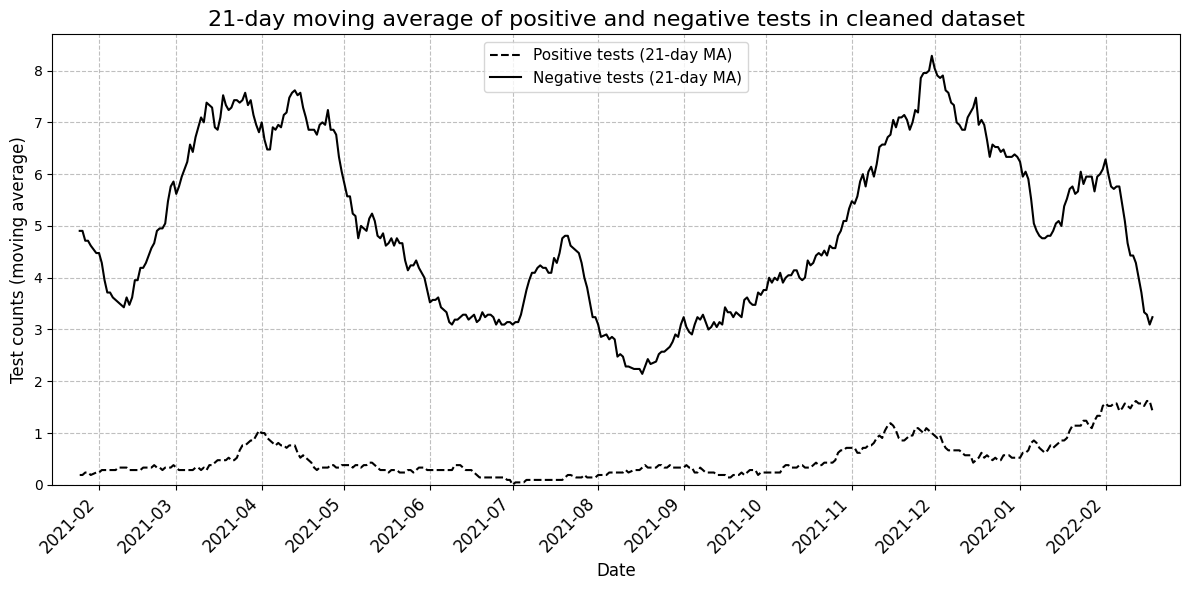

In [21]:
# Group by test date and sum the positivetest and negativetest columns
grouped_data = df_max2.groupby('T0_date').agg(
    positivetest_sum=('positivetest', 'sum'),
    negativetest_sum=('negativetest', 'sum')
)

# Compute a 21-day moving average for both columns
grouped_data['positivetest_ma'] = grouped_data['positivetest_sum'].rolling(window=21, center=True).mean()
grouped_data['negativetest_ma'] = grouped_data['negativetest_sum'].rolling(window=21, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(grouped_data.index, grouped_data['positivetest_ma'], color='black', linestyle='--', label='Positive tests (21-day MA)', linewidth=1.5)
ax.plot(grouped_data.index, grouped_data['negativetest_ma'], color='black', linestyle='-', label='Negative tests (21-day MA)', linewidth=1.5)

ax.set_xlim(grouped_data.index.min(), grouped_data.index.max())
ax.set_ylim(0)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.set_title('21-day moving average of positive and negative tests in cleaned dataset', fontsize=16)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Test counts (moving average)', fontsize=12)
ax.tick_params(axis='x', rotation=45, labelsize=12)
for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')
ax.grid(which='major', axis='both', linestyle='--', alpha=0.8)
#ax.grid(True)
ax.legend(fontsize=11)
plt.tight_layout()

plt.savefig("results/positive_negative_tests_ma.png", dpi=200, bbox_inches='tight')
plt.show()